**Mila Marsot**
# HW2 · Part 2: Single Stock Analysis Notebook

This notebook builds a risk report for one stock over a chosen period, using the clean table `ohlc_hw_cleaned` from Part 1. It computes returns, volatility, drawdown and the Sharpe ratio, then shows them in four charts and a summary table.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import sqlite3
import scrapbook as sb
from contextlib import closing
from pathlib import Path
from IPython.display import display
%matplotlib inline
plt.style.use('seaborn-v0_8-whitegrid')

## 2.1 Parameters
This cell has the tag `parameters`. When Part 3 runs the notebook with papermill, it replaces these values with the ticker and dates of each report.

In [2]:
# Parameters
ticker = 'AAPL'  # Stock ticker to analyze
start_date = '2024-01-01'  # Analysis start date
end_date = '2024-12-31'  # Analysis end date
db_path = 'data/data.db'  # Database containing ohlc_hw_cleaned (created in Part 1)
volatility_window = 20  # Rolling window, in trading days

## 2.2 Loading the data

I load the chosen stock and dates from `ohlc_hw_cleaned`. The code stops with a clear message if the database is missing, if the dates are in the wrong order, or if there are not enough prices: 20 returns need at least 21 prices.

Some stocks end earlier than others in the database, so I print the dates actually available, not only the ones requested.

In [3]:
database = Path(db_path).expanduser().resolve()
if not database.is_file():
    raise FileNotFoundError(f'Database not found at {database}: run 01_data_cleaning.ipynb first')
if pd.Timestamp(start_date) > pd.Timestamp(end_date):
    raise ValueError('start_date must be on or before end_date.')

query = """
SELECT ts, open, high, low, close, adj_close, volume
FROM ohlc_hw_cleaned WHERE ticker = ? AND ts >= ? AND ts <= ? ORDER BY ts
"""
with closing(sqlite3.connect(database.as_uri() + '?mode=ro', uri=True)) as conn:
    df = pd.read_sql_query(query, conn, params=(ticker, start_date, end_date), parse_dates=['ts'], index_col='ts')

if len(df) < volatility_window + 1:
    raise ValueError(f'{ticker}: need at least {volatility_window + 1} prices for {volatility_window} returns; got {len(df)}.')

first_date, last_date = df.index.min().date(), df.index.max().date()
print(f'{ticker} from {start_date} to {end_date}: {len(df)} trading days')
print(f'First and last observation: {first_date} to {last_date}')
if df.index.max() < pd.Timestamp(end_date) - pd.Timedelta(days=5):
    print(f'Note: the data for {ticker} stops on {last_date}, before the requested end date.')
display(df.head())
display(df.tail())

AAPL from 2024-01-01 to 2024-12-31: 202 trading days
First and last observation: 2024-01-02 to 2024-10-18
Note: the data for AAPL stops on 2024-10-18, before the requested end date.


,open,high,low,close,adj_close,volume
ts,,,,,,
2024-01-02,187.15,188.44,183.89,185.64,184.94,82488674
2024-01-03,184.22,185.88,183.43,184.25,183.55,58414460
2024-01-04,182.15,183.09,180.88,181.91,181.22,71983570
2024-01-05,181.99,182.76,180.17,181.18,180.50,62379661
2024-01-08,182.09,185.60,181.50,185.56,184.86,59144470


,open,high,low,close,adj_close,volume
ts,,,,,,
2024-10-14,228.70,231.73,228.60,231.30,231.30,39882100
2024-10-15,233.61,237.49,232.37,233.85,233.85,64751400
2024-10-16,231.60,232.12,229.84,231.78,231.78,34082240
2024-10-17,233.43,233.85,230.52,232.15,232.15,32993810
2024-10-18,236.18,236.18,234.01,235.00,235.00,45441281


### Checking the data

Before computing anything, I check that the prices are complete and positive, that the open and close are between the low and the high, that the volume is not negative and that no date appears twice. The notebook stops if a check fails.

In [4]:
def quality_flags(frame):
    """Flag missing/non-finite values, nonpositive prices, bad OHLC, negative volume and duplicate dates."""
    price_cols = ['open', 'high', 'low', 'close', 'adj_close']
    flags = pd.DataFrame(index=frame.index)
    flags['missing_or_nonfinite'] = ~np.isfinite(frame[price_cols + ['volume']]).all(axis=1)
    flags['nonpositive_price'] = frame[price_cols].le(0).any(axis=1)
    flags['ohlc_bounds'] = (frame['high'].lt(frame[['open', 'close']].max(axis=1))
                            | frame['low'].gt(frame[['open', 'close']].min(axis=1))
                            | frame['high'].lt(frame['low']))
    flags['negative_volume'] = frame['volume'].lt(0)
    flags['duplicate_date'] = frame.index.duplicated(keep=False)
    return flags


quality = quality_flags(df)
display(quality.sum().rename('rows with issue').to_frame().T)
if quality.any().any():
    raise ValueError('Data quality checks failed: ' + str(quality.sum().to_dict()))

,missing_or_nonfinite,nonpositive_price,ohlc_bounds,negative_volume,duplicate_date
rows with issue,0,0,0,0,0


## 2.3 Risk metrics

All the metrics use the **adjusted close**, which takes dividends into account.

| Function | What it computes |
|---|---|
| `calculate_returns` | Daily log return: `log(price / previous price)` |
| `calculate_volatility` | Standard deviation of the last 20 daily returns, times `sqrt(252)` to express it per year |
| `calculate_max_drawdown` | For each date, how far the price is below its highest level so far (0 at a new high) |
| `calculate_sharpe_ratio` | `(252 × average return − 2%) / (sqrt(252) × standard deviation)`: return per unit of risk |

The Sharpe ratio is `NaN` when it cannot be computed (fewer than two returns, or no volatility).

In [5]:
def calculate_returns(prices: pd.Series) -> pd.Series:
    """Calculate daily log returns; the first value is missing."""
    return np.log(prices / prices.shift(1))


def calculate_volatility(returns: pd.Series, window: int = 20) -> pd.Series:
    """Calculate annualized rolling volatility; missing until a full window is available."""
    return returns.rolling(window).std() * np.sqrt(252)


def calculate_max_drawdown(prices: pd.Series) -> pd.Series:
    """Return the drawdown at each date: price / running peak - 1."""
    return prices / prices.cummax() - 1


def calculate_sharpe_ratio(returns: pd.Series, risk_free_rate: float = 0.02) -> float:
    """Calculate the annualized Sharpe ratio of daily log returns; NaN when undefined."""
    observed = returns.dropna()
    sigma = observed.std()
    if len(observed) < 2 or not np.isfinite(sigma) or np.isclose(sigma, 0):
        return np.nan
    return (observed.mean() * 252 - risk_free_rate) / (sigma * np.sqrt(252))

I check the functions on a few prices that are easy to work out by hand: for 100, 110, 99, 105, the running peak is 110 from the second day, so the drawdown at 99 is −10%.

In [6]:
small = pd.Series([100.0, 110.0, 99.0, 105.0])
display(pd.DataFrame({'price': small, 'log_return': calculate_returns(small),
                      'running_peak': small.cummax(), 'drawdown': calculate_max_drawdown(small)}))
assert np.isclose(calculate_max_drawdown(small).min(), -0.10)
assert np.isclose(calculate_returns(small).sum(), np.log(105 / 100))
assert pd.isna(calculate_sharpe_ratio(pd.Series([0.01, 0.01])))

,price,log_return,running_peak,drawdown
0,100.0,NaN,100.0,0.000000
1,110.0,0.095310,110.0,0.000000
2,99.0,-0.105361,110.0,-0.100000
3,105.0,0.058841,110.0,-0.045455


Now I apply the functions to the stock. I also compute the 50-day moving average of the price. The rolling values stay empty at the start of the period (the "warm-up"): the volatility needs 21 prices and the moving average needs 50. I don't fill these gaps.

In [7]:
df['log_return'] = calculate_returns(df['adj_close'])
df['volatility'] = calculate_volatility(df['log_return'], volatility_window)
df['drawdown'] = calculate_max_drawdown(df['adj_close'])
df['sma_50'] = df['adj_close'].rolling(50).mean()

returns = df['log_return'].dropna()
sharpe_ratio = calculate_sharpe_ratio(returns)
max_drawdown = df['drawdown'].min()
mean_volatility = df['volatility'].mean()

print(f'Sharpe ratio: {sharpe_ratio:.2f}')
print(f'Maximum drawdown: {max_drawdown:.2%} on {df["drawdown"].idxmin().date()}')
print(f'Mean rolling volatility: {mean_volatility:.2%}')
if df['sma_50'].isna().all():
    print(f'Only {len(df)} prices: the 50-day moving average is not available for this period.')
display(df[['adj_close', 'log_return', 'volatility', 'drawdown', 'sma_50']].tail())

Sharpe ratio: 1.19
Maximum drawdown: -15.35% on 2024-04-19
Mean rolling volatility: 23.36%


,adj_close,log_return,volatility,drawdown,sma_50
ts,,,,,
2024-10-14,231.30,0.016346,0.242503,-0.013856,223.6422
2024-10-15,233.85,0.010964,0.243942,-0.002984,224.1386
2024-10-16,231.78,-0.008891,0.241973,-0.011810,224.6344
2024-10-17,232.15,0.001595,0.206097,-0.010232,225.0858
2024-10-18,235.00,0.012202,0.209521,0.000000,225.5246


## 2.4 Charts

The four charts share the same dates:

- **Top left:** the adjusted price, with its 50-day moving average. Each segment of the price line is red when the rolling volatility is above its average over the period, green otherwise, and gray before the volatility is available.
- **Top right:** the daily returns, green when positive and red when negative.
- **Bottom left:** the 20-day rolling volatility with its average (dashed line). Red areas are periods of high volatility, green areas periods of low volatility.
- **Bottom right:** the drawdown. Several transparent red layers give a gradient, and the black dot marks the maximum drawdown.

The colors use the average over the whole period, so they describe the past and could not have been known in real time.

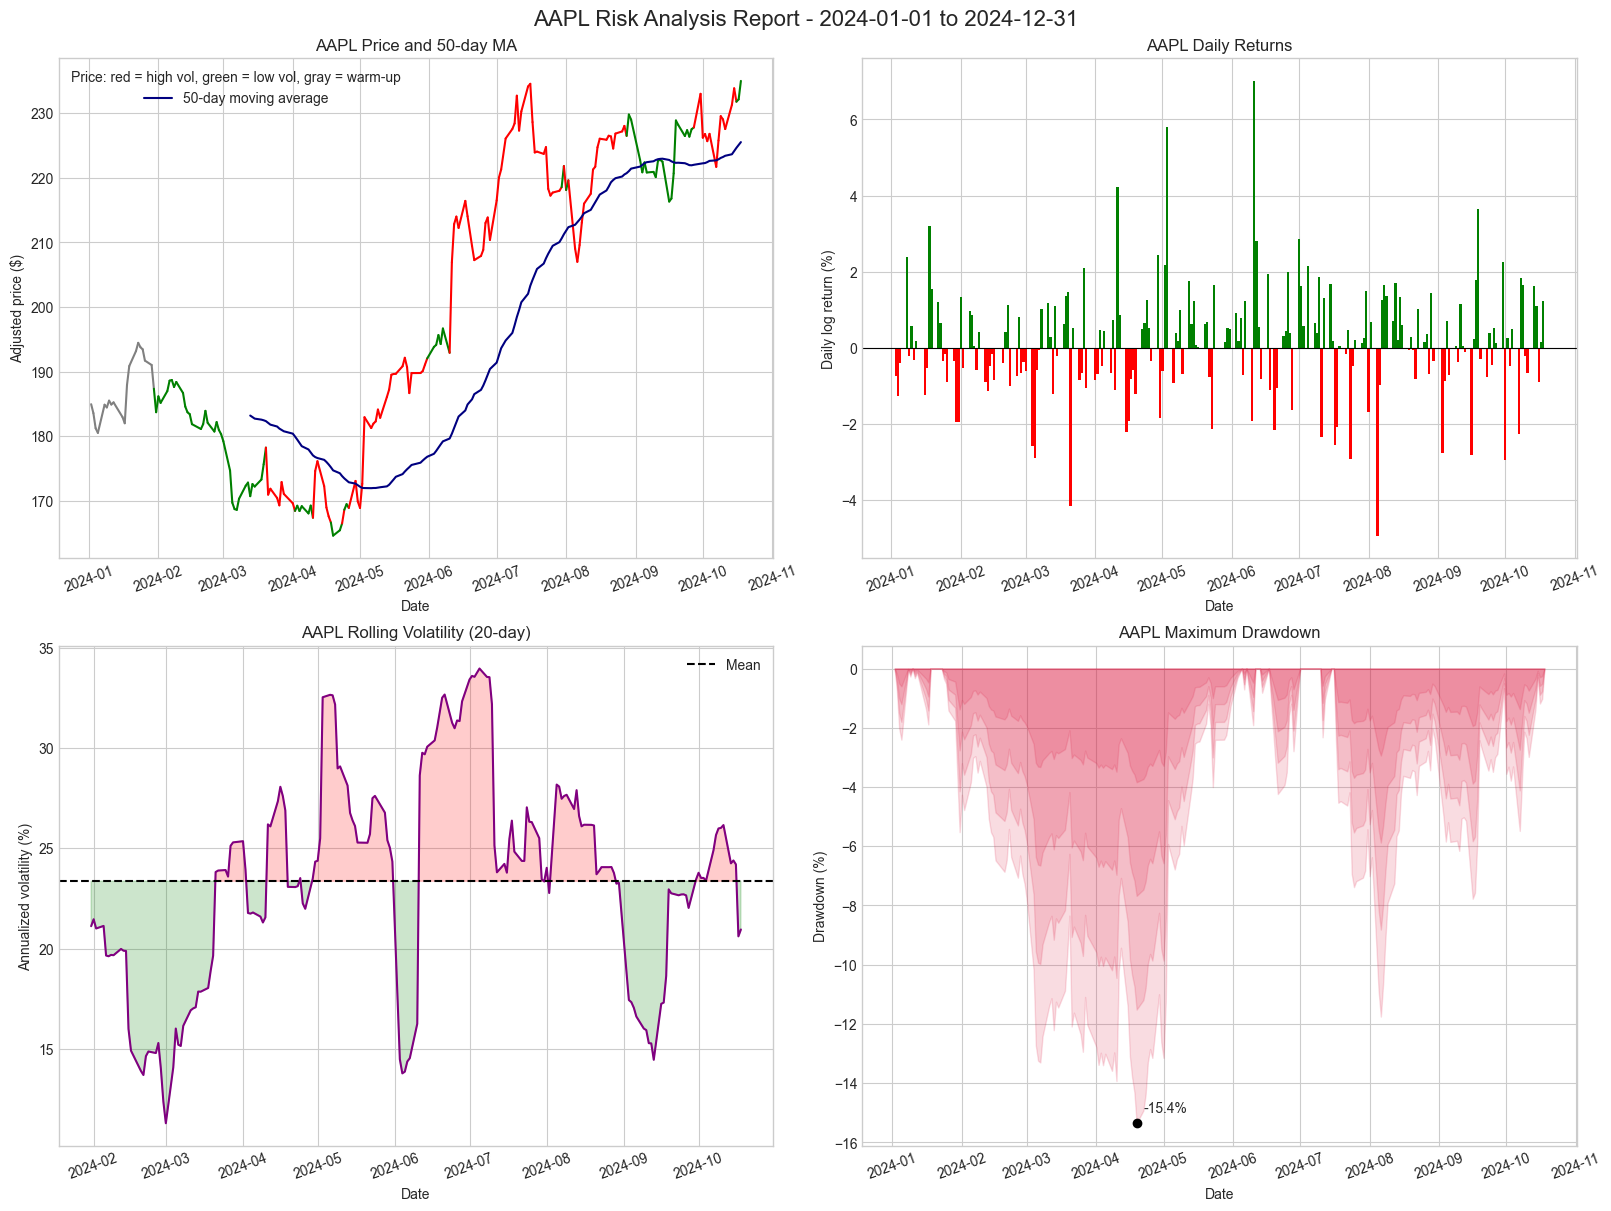

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(16, 12), layout='constrained')
fig.suptitle(f'{ticker} Risk Analysis Report - {start_date} to {end_date}', fontsize=16)

# Price, colored by volatility; gray means the rolling estimate is not available yet
for i in range(1, len(df)):
    vol = df['volatility'].iloc[i]
    color = 'gray' if pd.isna(vol) else ('red' if vol > mean_volatility else 'green')
    axes[0, 0].plot(df.index[i-1:i+1], df['adj_close'].iloc[i-1:i+1], color=color)
axes[0, 0].plot(df.index, df['sma_50'], color='navy', label='50-day moving average')
axes[0, 0].set(title=f'{ticker} Price and 50-day MA', ylabel='Adjusted price ($)')
axes[0, 0].legend(title='Price: red = high vol, green = low vol, gray = warm-up')

# Daily returns: green when positive, red when negative
axes[0, 1].bar(df.index, df['log_return'] * 100, width=1,
               color=np.where(df['log_return'].ge(0), 'green', 'red'))
axes[0, 1].axhline(0, color='black', linewidth=0.8)
axes[0, 1].set(title=f'{ticker} Daily Returns', ylabel='Daily log return (%)')

# Rolling volatility, with high and low regions shaded around the mean
vol_pct = df['volatility'] * 100
axes[1, 0].plot(df.index, vol_pct, color='purple')
axes[1, 0].axhline(mean_volatility * 100, color='black', linestyle='--', label='Mean')
for condition, color in [(df['volatility'] > mean_volatility, 'red'),
                         (df['volatility'] <= mean_volatility, 'green')]:
    axes[1, 0].fill_between(df.index, vol_pct, mean_volatility * 100,
                            where=condition, color=color, alpha=0.2, interpolate=True)
axes[1, 0].set(title=f'{ticker} Rolling Volatility ({volatility_window}-day)', ylabel='Annualized volatility (%)')
axes[1, 0].legend()

# Drawdown: layered transparent fills make a red gradient; the black dot is the maximum drawdown
drawdown_pct = df['drawdown'] * 100
for fraction in [1.0, 0.75, 0.5, 0.25]:
    axes[1, 1].fill_between(df.index, drawdown_pct * fraction, 0, color='crimson', alpha=0.15)
worst_date = df['drawdown'].idxmin()
axes[1, 1].scatter([worst_date], [drawdown_pct.loc[worst_date]], color='black', zorder=3)
axes[1, 1].annotate(f'{drawdown_pct.loc[worst_date]:.1f}%', (worst_date, drawdown_pct.loc[worst_date]),
                    xytext=(5, 8), textcoords='offset points')
axes[1, 1].set(title=f'{ticker} Maximum Drawdown', ylabel='Drawdown (%)')

for ax in axes.flat:
    ax.set_xlabel('Date')
    ax.grid(True)
    ax.tick_params(axis='x', labelrotation=20)
plt.show()

## 2.5 Summary statistics

| Metric | How it is computed |
|---|---|
| Total Return | last adjusted close / first adjusted close − 1 |
| Annualized Return | `exp(sum of log returns × 252 / number of returns) − 1` |
| Annualized Volatility | standard deviation of all daily log returns × `sqrt(252)` |
| Sharpe Ratio | `calculate_sharpe_ratio` |
| Maximum Drawdown | lowest value of the drawdown |
| Best Day / Worst Day | largest and smallest daily log return |
| Positive Days | share of returns above 0, out of all returns (including days at 0) |
| Average Up Day / Down Day | average of the positive / negative daily log returns |

I keep the values as fractions and only format them as percentages for display. A value that cannot be computed is shown as N/A.

In [9]:
total_return = df['adj_close'].iloc[-1] / df['adj_close'].iloc[0] - 1
annualized_return = np.exp(returns.sum() * 252 / len(returns)) - 1
annualized_volatility = returns.std() * np.sqrt(252)

summary = pd.Series({
    'Total Return': total_return,
    'Annualized Return': annualized_return,
    'Annualized Volatility': annualized_volatility,
    'Sharpe Ratio': sharpe_ratio,
    'Maximum Drawdown': max_drawdown,
    'Best Day': returns.max(),
    'Worst Day': returns.min(),
    'Positive Days': returns.gt(0).mean(),
    'Average Up Day': returns[returns > 0].mean(),
    'Average Down Day': returns[returns < 0].mean(),
})


def format_metric(metric, value):
    """Format a metric for display: N/A, a plain number or a percentage."""
    if pd.isna(value):
        return 'N/A'
    if metric == 'Sharpe Ratio':
        return f'{value:.2f}'
    if metric in ['Annualized Volatility', 'Positive Days']:
        return f'{value:.2%}'
    return f'{value:+.2%}'


summary_table = pd.DataFrame({'Value': [format_metric(m, v) for m, v in summary.items()]},
                             index=pd.Index(summary.index, name='Metric'))
display(summary_table)

,Value
Metric,
Total Return,+27.07%
Annualized Return,+35.03%
Annualized Volatility,23.61%
Sharpe Ratio,1.19
Maximum Drawdown,-15.35%
Best Day,+7.01%
Worst Day,-4.94%
Positive Days,55.72%
Average Up Day,+1.08%


### Saving the results for Part 3

`sb.glue` saves named values inside the executed notebook. Part 3 reads them back from each report to build the portfolio summary, without computing everything again.

In [10]:
sb.glue('ticker', ticker)
sb.glue('first_date', str(first_date))
sb.glue('last_date', str(last_date))
sb.glue('trading_days', len(df))
sb.glue('avg_daily_return', float(returns.mean()))
sb.glue('avg_volatility', float(mean_volatility))
sb.glue('max_drawdown', float(max_drawdown))
sb.glue('sharpe_ratio', float(sharpe_ratio))
sb.glue('total_return', float(total_return))
print('Results saved for the portfolio summary.')

Results saved for the portfolio summary.


In VS Code these saved values show “No renderer could be found”: this is expected, Part 3 reads them.